# Comparación y evaluación de modelos de Cassava

Se comparan los representantes seleccionados de CNN propia,
MobileNetV2, EfficientNetB0 y DenseNet121.

La evaluación considera exactitud, precisión, recall, F1 macro,
ROC-AUC, pérdida, desempeño por clase, matrices de confusión,
curvas de entrenamiento y costo computacional.

Se conserva la comparación sobre las 1.889 imágenes originales
de Validation. Adicionalmente, se revisan las mismas predicciones
excluyendo 12 imágenes idénticas a imágenes de Train,
confirmadas mediante sus dimensiones y píxeles originales.

Esta revisión adicional utiliza las mismas 1.877 imágenes
para los cuatro modelos y no modifica las particiones guardadas.

No se realizan nuevos entrenamientos ni se evalúa Test.
La selección se justificará mediante el conjunto de evidencias,
sin asignar un ganador automáticamente por una sola métrica.

In [1]:
# PASO 1: Importaciones de la comparación de Cassava.
import csv
import json
from pathlib import Path
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras

print("TensorFlow:", tf.__version__)
print("Evaluación de modelos guardados; no habrá entrenamiento.")

TensorFlow: 2.21.0
Evaluación de modelos guardados; no habrá entrenamiento.


In [12]:
# PASO 2: Localizar modelos, historiales y tiempos.
actual = Path.cwd()
carpeta_cassava = (
    actual if actual.name.lower() == "cassava"
    else actual / "cassava"
)

if not (carpeta_cassava / "Preparacion_Cassava.ipynb").is_file():
    raise FileNotFoundError(
        "Ejecuta desde la raíz de BeanCass AI o desde cassava."
    )

raiz = carpeta_cassava / "resultados"
clases = ["cbb", "cbsd", "cgm", "cmd", "healthy"]


def leer_json(ruta):
    with ruta.open(encoding="utf-8-sig") as archivo:
        return json.load(archivo)


def leer_historial(carpeta):
    with (carpeta / "historial.csv").open(
        encoding="utf-8-sig", newline=""
    ) as archivo:
        filas = [
            f for f in csv.DictReader(archivo)
            if f.get("epoch") not in (None, "")
        ]

    if not filas:
        raise ValueError(f"Historial vacío: {carpeta}")

    return filas


cnn = (
    raiz
    / "cnn_propia_ajustada"
    / "ensayo_07_lote32_lr0005_20261121_081009_141455"
)

mobile = (
    raiz / "mobilenetv2"
    / "ajuste_fino_20261117_205820_216835"
)

efficient = (
    raiz / "efficientnetb0"
    / "ajuste_fino_20261116_203639"
)

dense = (
    raiz / "densenet121"
    / "ajuste_fino_ultimo_bloque_20261121_145133_397719"
)

mobile_base = (
    raiz / "mobilenetv2"
    / "corrida_20261117_041049_112297"
)

efficient_base = (
    raiz / "efficientnetb0"
    / "ponderada_moderada_20261116_202619"
)

dense_origen = (
    raiz / "densenet121"
    / "continuacion_congelada_20261121_141219_063524"
)

with (
    raiz / "densenet121/comparacion_torneo_densenet121.csv"
).open(encoding="utf-8-sig", newline="") as archivo:
    tiempo_dense = next(
        float(f["minutos_acumulados_aprox"])
        for f in csv.DictReader(archivo)
        if int(f["ensayo"]) == 6
    )
with (raiz / "efficientnetb0" / "tiempos_entrenamiento.csv").open(
    encoding="utf-8-sig", newline=""
) as archivo:
    tiempo_efficient = next(
        float(f["tiempo_min"])
        for f in csv.DictReader(archivo)
        if f["ensayo"] == "2+3"
    )

finalistas = [
    {
        "nombre": "CNN propia",
        "carpeta": cnn,
        "previo": None,
        "hasta": 0,
        "minutos": 45.40,
    },
    {
        "nombre": "MobileNetV2",
        "carpeta": mobile,
        "previo": mobile_base,
        "hasta": 4,
        "minutos": sum(
            leer_json(p / "entrenamiento.json")[
                "tiempo_entrenamiento_segundos"
            ]
            for p in (mobile_base, mobile)
        ) / 60,
    },
    {
        "nombre": "EfficientNetB0",
        "carpeta": efficient,
        "previo": efficient_base,
        "hasta": 4,
        "minutos": tiempo_efficient,
    },
    {
        "nombre": "DenseNet121",
        "carpeta": dense,
        "previo": dense_origen,
        "hasta": 8,
        "minutos": tiempo_dense,
    },
]

for candidato in finalistas:
    for nombre in ("mejor_modelo.keras", "historial.csv"):
        ruta = candidato["carpeta"] / nombre
        if not ruta.is_file():
            raise FileNotFoundError(ruta)

    if candidato["previo"] is not None:
        filas_previas = leer_historial(candidato["previo"])
        mejor_previa = min(
            filas_previas,
            key=lambda f: float(f["val_loss"]),
        )
        epoca_origen = int(mejor_previa["epoch"]) + 1

        if epoca_origen != candidato["hasta"]:
            raise ValueError(
                f"Revisar checkpoint de origen: {candidato['nombre']}"
            )

    print(
        candidato["nombre"], "→",
        candidato["carpeta"].name,
    )

salida = (
    raiz / "comparacion_modelos"
    / datetime.now().strftime("validation_%Y%m%d_%H%M%S_%f")
)
salida.mkdir(parents=True, exist_ok=False)

print("\nResultados nuevos en:", salida.resolve())
print(f"Tiempo de EfficientNetB0 registrado: {tiempo_efficient:.2f} min.")
print("Los tiempos de CNN propia y DenseNet121 son aproximados.")

CNN propia → ensayo_07_lote32_lr0005_20261121_081009_141455
MobileNetV2 → ajuste_fino_20261117_205820_216835
EfficientNetB0 → ajuste_fino_20261116_203639
DenseNet121 → ajuste_fino_ultimo_bloque_20261121_145133_397719

Resultados nuevos en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\comparacion_modelos\validation_20261122_182852_477368
Tiempo de EfficientNetB0 registrado: 20.88 min.
Los tiempos de CNN propia y DenseNet121 son aproximados.


In [3]:
# PASO 3: Cargar únicamente Validation y preparar la revisión común.
ds_val, info = tfds.load(
    "cassava:0.1.0",
    split="validation",
    with_info=True,
    as_supervised=False,
    shuffle_files=False,
)

if list(info.features["label"].names) != clases:
    raise ValueError(
        "El orden de clases no coincide con Cassava."
    )

coincidencias_train = {
    "validation-cbsd-339.jpg",
    "validation-cbb-134.jpg",
    "validation-cbb-94.jpg",
    "validation-cbsd-148.jpg",
    "validation-cgm-84.jpg",
    "validation-cbb-86.jpg",
    "validation-cbsd-72.jpg",
    "validation-cbsd-300.jpg",
    "validation-cmd-291.jpg",
    "validation-cbb-152.jpg",
    "validation-cmd-813.jpg",
    "validation-cbb-142.jpg",
}

identificadores, etiquetas_lista = [], []

for registro in ds_val:
    identificadores.append(
        registro["image/filename"].numpy().decode("utf-8")
    )
    etiquetas_lista.append(
        int(registro["label"].numpy())
    )

reales_eval = np.asarray(etiquetas_lista, dtype=int)

if not np.array_equal(
    np.bincount(reales_eval, minlength=5),
    [156, 482, 258, 887, 106],
):
    raise ValueError(
        "La partición no coincide con Validation de Cassava."
    )

if not coincidencias_train.issubset(set(identificadores)):
    raise ValueError(
        "No se encontraron todas las coincidencias documentadas."
    )

sin_coincidencias = np.array([
    nombre not in coincidencias_train
    for nombre in identificadores
])

if int(sin_coincidencias.sum()) != 1877:
    raise ValueError("Revisar las 12 coincidencias conocidas.")


def preparar_validacion(registro):
    imagen = tf.image.resize_with_pad(
        registro["image"], 224, 224, antialias=True
    )
    return (
        tf.clip_by_value(imagen, 0.0, 255.0),
        registro["label"],
        registro["image/filename"],
    )


datos_eval = (
    ds_val
    .map(
        preparar_validacion,
        num_parallel_calls=tf.data.AUTOTUNE,
        deterministic=True,
    )
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

with (salida / "imagenes_validation.csv").open(
    "w", encoding="utf-8-sig", newline=""
) as archivo:
    escritor = csv.writer(archivo)
    escritor.writerow([
        "imagen",
        "clase_real",
        "coincidencia_exacta_con_train",
    ])
    escritor.writerows(
        (nombre, clases[etiqueta], nombre in coincidencias_train)
        for nombre, etiqueta in zip(identificadores, reales_eval)
    )

with (salida / "protocolo.json").open(
    "w", encoding="utf-8"
) as archivo:
    json.dump(
        {
            "dataset": "cassava:0.1.0",
            "imagenes_validation": 1889,
            "imagenes_sin_coincidencias_conocidas": 1877,
            "coincidencias_exactas_train_validation": sorted(
                coincidencias_train
            ),
            "revision_coincidencias": (
                "SHA-256 de dimensiones y píxeles originales; "
                "lista reconfirmada"
            ),
            "test_evaluado_en_esta_comparacion": False,
            "modelos_relativos_a_cassava": {
                c["nombre"]: str(
                    c["carpeta"].relative_to(carpeta_cassava)
                )
                for c in finalistas
            },
        },
        archivo,
        ensure_ascii=False,
        indent=2,
    )

print("Validation completa:", len(reales_eval), "imágenes.")
print(
    "Conteos por clase:",
    np.bincount(reales_eval, minlength=5),
)
print(
    "Revisión sin coincidencias exactas conocidas:",
    int(sin_coincidencias.sum()),
)
print("Imágenes RGB de 224 × 224; píxeles float32 entre 0 y 255.")
print("Test no se evaluará.")

Validation completa: 1889 imágenes.
Conteos por clase: [156 482 258 887 106]
Revisión sin coincidencias exactas conocidas: 1877
Imágenes RGB de 224 × 224; píxeles float32 entre 0 y 255.
Test no se evaluará.


In [4]:
# PASO 4: Evaluar los modelos y guardar tablas y predicciones.
def auc_binaria(etiquetas, puntuaciones):
    positivos = puntuaciones[etiquetas]
    negativos = puntuaciones[~etiquetas]

    return float(
        (positivos[:, None] > negativos[None, :]).mean()
        + 0.5 * (
            positivos[:, None] == negativos[None, :]
        ).mean()
    )


def resumir_evaluacion(
    candidato, probabilidades, reales, conjunto
):
    predichas = probabilidades.argmax(axis=1)
    matriz = np.zeros((5, 5), dtype=int)
    np.add.at(matriz, (reales, predichas), 1)

    aciertos = matriz.diagonal()
    totales = matriz.sum(axis=1)
    predicciones = matriz.sum(axis=0)

    precision = aciertos / np.maximum(predicciones, 1)
    recall = aciertos / totales
    f1 = 2 * aciertos / np.maximum(
        totales + predicciones, 1
    )

    resultado = {
        "modelo": candidato["nombre"],
        "conjunto": conjunto,
        "imagenes": len(reales),
        "exactitud": float(aciertos.sum() / len(reales)),
        "precision_macro": float(precision.mean()),
        "recall_macro": float(recall.mean()),
        "f1_macro": float(f1.mean()),
        "roc_auc_macro_ovr": float(np.mean([
            auc_binaria(
                reales == i, probabilidades[:, i]
            )
            for i in range(5)
        ])),
        "perdida": float(-np.log(np.clip(
            probabilidades[
                np.arange(len(reales)), reales
            ],
            1e-7, 1,
        )).mean()),
        "enfermas_como_sanas": int(matriz[:4, 4].sum()),
        "minutos_train_acumulados": candidato["minutos"],
    }

    detalle = {
        "matriz": matriz.tolist(),
        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),
    }

    return resultado, detalle


resultados = []
resultados_sin_coincidencias = []
detalles = {}

for candidato in finalistas:
    nombre = candidato["nombre"]
    print(f"Evaluando {nombre}...", flush=True)

    keras.backend.clear_session()
    modelo = keras.models.load_model(
        candidato["carpeta"] / "mejor_modelo.keras",
        compile=False,
    )

    partes = []
    etiquetas_comprobadas = []
    nombres_comprobados = []

    for imagenes, etiquetas, archivos in datos_eval:
        partes.append(
            modelo(imagenes, training=False).numpy()
        )
        etiquetas_comprobadas.extend(
            etiquetas.numpy().tolist()
        )
        nombres_comprobados.extend(
            n.decode("utf-8")
            for n in archivos.numpy()
        )

    probabilidades = np.concatenate(partes)

    if (
        probabilidades.shape != (1889, 5)
        or not np.isfinite(probabilidades).all()
        or np.any(probabilidades < 0)
        or np.any(probabilidades > 1)
        or not np.allclose(
            probabilidades.sum(axis=1), 1, atol=1e-4
        )
    ):
        raise ValueError(
            f"Predicciones inválidas en {nombre}."
        )

    if (
        nombres_comprobados != identificadores
        or not np.array_equal(
            etiquetas_comprobadas, reales_eval
        )
    ):
        raise ValueError(
            "Los modelos no recibieron las mismas imágenes "
            "y etiquetas en el mismo orden."
        )

    resultado, detalle = resumir_evaluacion(
        candidato,
        probabilidades,
        reales_eval,
        "validation_completa",
    )

    registros = leer_historial(candidato["carpeta"])
    mejor = min(
        registros,
        key=lambda f: float(f["val_loss"]),
    )

    if abs(
        resultado["exactitud"]
        - float(mejor["val_accuracy"])
    ) > 0.0001:
        raise ValueError(
            f"{nombre}: no reproduce la exactitud guardada. "
            "Revisar antes de continuar."
        )

    referencia = (
        candidato["carpeta"] / "metricas_validation.json"
    )
    if referencia.is_file():
        matriz_anterior = leer_json(referencia).get(
            "matriz_confusion"
        )
        if (
            matriz_anterior is not None
            and not np.array_equal(
                detalle["matriz"], matriz_anterior
            )
        ):
            raise ValueError(
                f"{nombre}: la matriz no coincide con la guardada."
            )

    referencia_csv = (
        candidato["carpeta"]
        / "matriz_confusion_validation.csv"
    )
    if referencia_csv.is_file():
        with referencia_csv.open(
            encoding="utf-8-sig", newline=""
        ) as archivo:
            filas_matriz = list(csv.reader(archivo))[1:]
            matriz_anterior = np.asarray(
                [f[1:] for f in filas_matriz],
                dtype=int,
            )

        if not np.array_equal(
            detalle["matriz"], matriz_anterior
        ):
            raise ValueError(
                f"{nombre}: la matriz no coincide con el CSV guardado."
            )

    revision, detalle_revision = resumir_evaluacion(
        candidato,
        probabilidades[sin_coincidencias],
        reales_eval[sin_coincidencias],
        "validation_sin_coincidencias_exactas_conocidas",
    )

    for fila in (resultado, revision):
        fila["parametros"] = int(modelo.count_params())
        fila["epoca_guardada_etapa"] = (
            int(mejor["epoch"]) + 1
        )

    resultados.append(resultado)
    resultados_sin_coincidencias.append(revision)
    detalles[nombre] = {
        **detalle,
        "sin_coincidencias": detalle_revision,
    }

    ruta_predicciones = (
        salida
        / f"predicciones_{nombre.replace(' ', '_')}.csv"
    )
    with ruta_predicciones.open(
        "w", encoding="utf-8-sig", newline=""
    ) as archivo:
        escritor = csv.writer(archivo)
        escritor.writerow(
            [
                "imagen", "real", "predicha",
                "coincidencia_exacta_con_train",
            ]
            + [f"prob_{c}" for c in clases]
        )

        predichas = probabilidades.argmax(axis=1)
        escritor.writerows(
            [
                n,
                clases[reales_eval[i]],
                clases[predichas[i]],
                n in coincidencias_train,
            ]
            + probabilidades[i].tolist()
            for i, n in enumerate(identificadores)
        )

    print(
        f"{nombre}: {resultado['exactitud']:.2%}"
        f" · F1 macro {resultado['f1_macro']:.4f}",
        flush=True,
    )
    del modelo

for nombre_archivo, tabla in (
    ("comparacion_validation.csv", resultados),
    (
        "comparacion_validation_sin_coincidencias.csv",
        resultados_sin_coincidencias,
    ),
):
    with (salida / nombre_archivo).open(
        "w", encoding="utf-8-sig", newline=""
    ) as archivo:
        escritor = csv.DictWriter(
            archivo, fieldnames=list(tabla[0])
        )
        escritor.writeheader()
        escritor.writerows(tabla)

with (salida / "detalle_por_clase.json").open(
    "w", encoding="utf-8"
) as archivo:
    json.dump(
        detalles, archivo,
        ensure_ascii=False, indent=2,
    )

for titulo, tabla in (
    (
        "VALIDATION COMPLETA · 1.889 IMÁGENES",
        resultados,
    ),
    (
        "SIN 12 COINCIDENCIAS EXACTAS CON TRAIN · 1.877 IMÁGENES",
        resultados_sin_coincidencias,
    ),
):
    print("\n" + titulo)
    print(
        "MODELO              ACC   P MACRO   R MACRO"
        "  F1 MACRO  ROC-AUC  PÉRDIDA  ENF→SANAS"
    )

    for r in tabla:
        print(
            f"{r['modelo']:<17}"
            f"{r['exactitud']:>8.2%}"
            f"{r['precision_macro']:>10.4f}"
            f"{r['recall_macro']:>10.4f}"
            f"{r['f1_macro']:>10.4f}"
            f"{r['roc_auc_macro_ovr']:>9.4f}"
            f"{r['perdida']:>9.4f}"
            f"{r['enfermas_como_sanas']:>11}"
        )

print(
    "\nMODELO             PARÁMETROS"
    "  MIN TRAIN ACUM.  ÉPOCA DE ETAPA"
)

for r in resultados:
    tiempo = (
        f"{r['minutos_train_acumulados']:.2f}"
        if r["minutos_train_acumulados"] is not None
        else "N/D"
    )
    print(
        f"{r['modelo']:<17}"
        f"{r['parametros']:>11}"
        f"{tiempo:>17}"
        f"{r['epoca_guardada_etapa']:>16}"
    )

print("\nPOR CLASE · VALIDATION COMPLETA")
print(
    "MODELO             CLASE      ACIERTOS"
    "   PRECISIÓN    RECALL       F1"
)

for nombre, detalle in detalles.items():
    matriz = np.asarray(detalle["matriz"])

    for i, clase in enumerate(clases):
        aciertos = (
            f"{matriz[i, i]}/{matriz[i].sum()}"
        )
        print(
            f"{nombre:<19}{clase:<9}{aciertos:>9}"
            f"{detalle['precision'][i]:>12.2%}"
            f"{detalle['recall'][i]:>10.2%}"
            f"{detalle['f1'][i]:>9.4f}"
        )

print(
    "\nLos tiempos originales no son una comparación "
    "controlada entre equipos."
)
print(
    "La revisión de coincidencias complementa "
    "la comparación original; no se utilizó Test."
)

Evaluando CNN propia...



CNN propia: 76.76% · F1 macro 0.6869
Evaluando MobileNetV2...
MobileNetV2: 80.84% · F1 macro 0.7505
Evaluando EfficientNetB0...
EfficientNetB0: 82.21% · F1 macro 0.7647
Evaluando DenseNet121...
DenseNet121: 79.51% · F1 macro 0.7295

VALIDATION COMPLETA · 1.889 IMÁGENES
MODELO              ACC   P MACRO   R MACRO  F1 MACRO  ROC-AUC  PÉRDIDA  ENF→SANAS
CNN propia         76.76%    0.6833    0.6934    0.6869   0.9357   0.6311         40
MobileNetV2        80.84%    0.7563    0.7503    0.7505   0.9515   0.5690         35
EfficientNetB0     82.21%    0.7698    0.7616    0.7647   0.9565   0.5142         32
DenseNet121        79.51%    0.7659    0.7092    0.7295   0.9428   0.5866         32

SIN 12 COINCIDENCIAS EXACTAS CON TRAIN · 1.877 IMÁGENES
MODELO              ACC   P MACRO   R MACRO  F1 MACRO  ROC-AUC  PÉRDIDA  ENF→SANAS
CNN propia         76.88%    0.6835    0.6950    0.6876   0.9378   0.6222         40
MobileNetV2        80.98%    0.7573    0.7512    0.7514   0.9528   0.5622         

CNN propia · inicio de etapa final: 1 · checkpoint en la trayectoria: 18
MobileNetV2 · inicio de etapa final: 5 · checkpoint en la trayectoria: 8
EfficientNetB0 · inicio de etapa final: 5 · checkpoint en la trayectoria: 7
DenseNet121 · inicio de etapa final: 9 · checkpoint en la trayectoria: 14


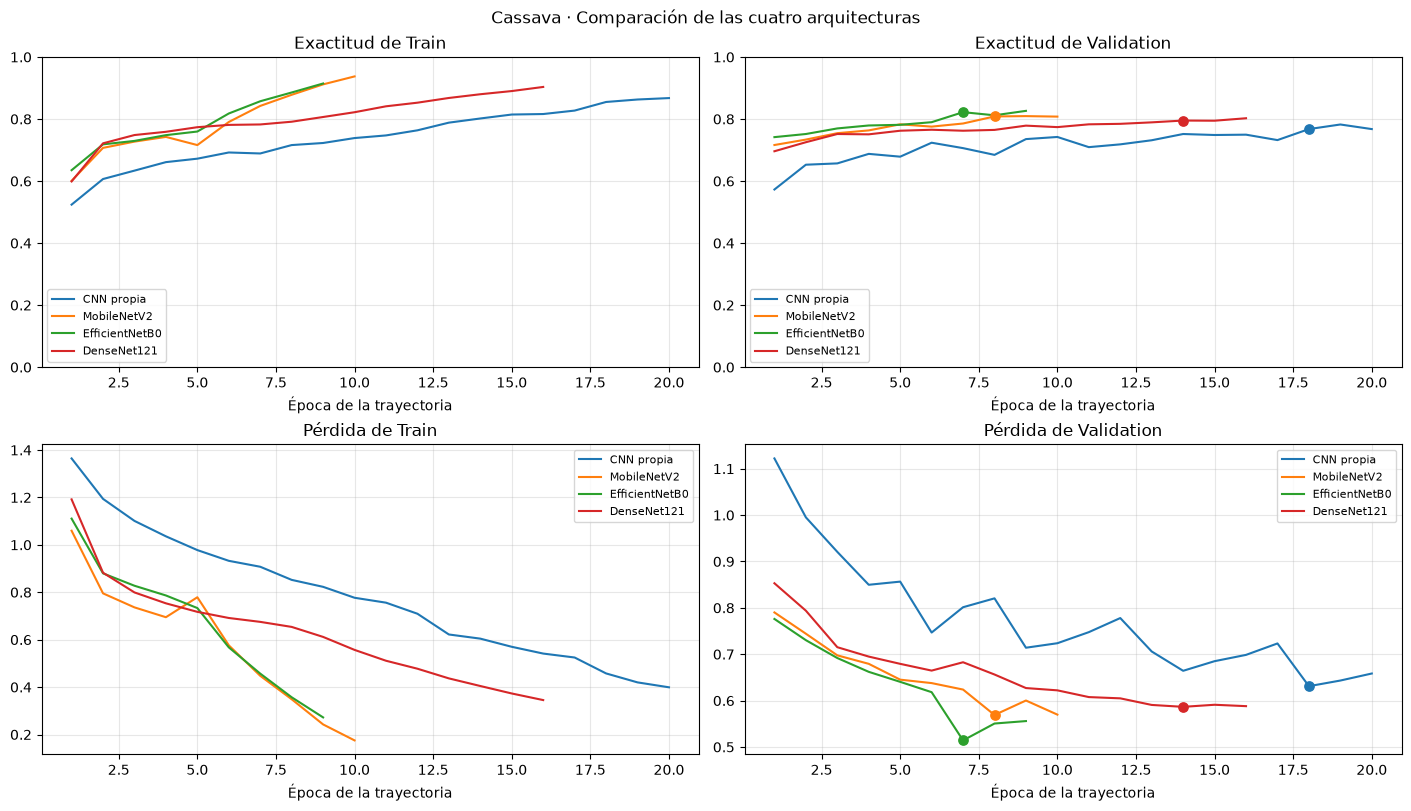

Los puntos de Validation identifican los checkpoints evaluados.
Las curvas utilizan Validation completa, incluidas las coincidencias documentadas.
Train y Validation utilizan condiciones diferentes.
Las épocas no representan el mismo tiempo ni capacidad entrenable.


In [5]:
# PASO 5: Curvas comparativas y checkpoints de los cuatro modelos.
fig, ejes = plt.subplots(
    2, 2, figsize=(14, 8), layout="constrained"
)
fig.suptitle(
    "Cassava · Comparación de las cuatro arquitecturas"
)

paneles = [
    ("accuracy", "Exactitud de Train"),
    ("val_accuracy", "Exactitud de Validation"),
    ("loss", "Pérdida de Train"),
    ("val_loss", "Pérdida de Validation"),
]

for k, candidato in enumerate(finalistas):
    anteriores = (
        leer_historial(candidato["previo"])[
            :candidato["hasta"]
        ]
        if candidato["previo"] is not None
        else []
    )

    etapa = leer_historial(candidato["carpeta"])
    trayectoria = anteriores + etapa
    epocas = np.arange(1, len(trayectoria) + 1)

    posicion_mejor = int(np.argmin([
        float(f["val_loss"]) for f in etapa
    ]))
    checkpoint = (
        len(anteriores) + posicion_mejor + 1
    )
    color = plt.get_cmap("tab10")(k)

    for eje, (campo, titulo) in zip(
        ejes.flat, paneles
    ):
        valores = [
            float(f[campo]) for f in trayectoria
        ]

        eje.plot(
            epocas, valores,
            color=color,
            label=candidato["nombre"],
        )

        if campo.startswith("val_"):
            eje.scatter(
                checkpoint,
                valores[checkpoint - 1],
                color=color,
                s=45,
                zorder=3,
            )

        eje.set(
            title=titulo,
            xlabel="Época de la trayectoria",
        )
        eje.grid(alpha=0.3)

        if "accuracy" in campo:
            eje.set_ylim(0, 1)

    print(
        f"{candidato['nombre']}"
        f" · inicio de etapa final: {len(anteriores) + 1}"
        f" · checkpoint en la trayectoria: {checkpoint}"
    )

for eje in ejes.flat:
    eje.legend(fontsize=8)

fig.savefig(
    salida / "curvas_comparativas.png",
    dpi=200,
)
plt.show()
plt.close(fig)

print(
    "Los puntos de Validation identifican "
    "los checkpoints evaluados."
)
print(
    "Las curvas utilizan Validation completa, "
    "incluidas las coincidencias documentadas."
)
print("Train y Validation utilizan condiciones diferentes.")
print(
    "Las épocas no representan el mismo tiempo "
    "ni capacidad entrenable."
)

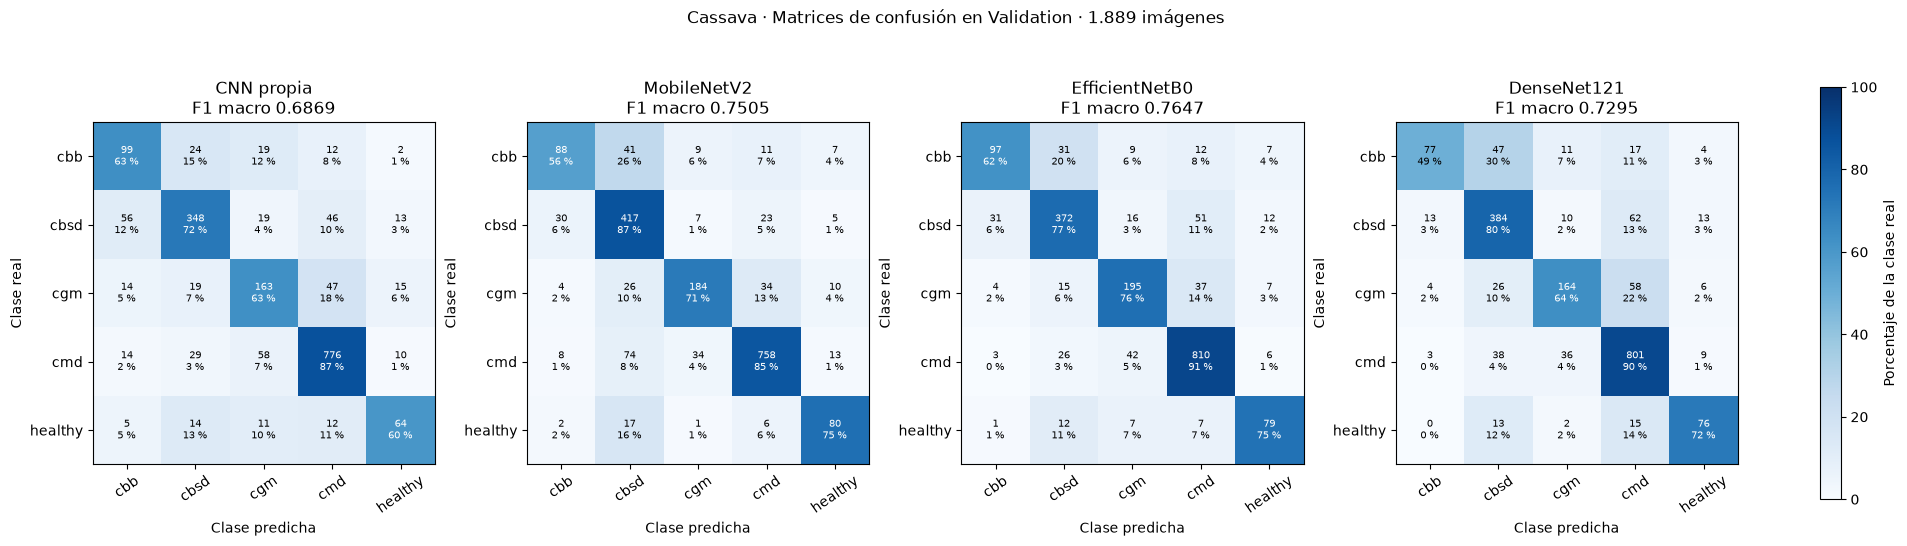

Filas: clase real. Columnas: clase predicha.
Comparación terminada. Todavía no se registró un ganador.
La decisión revisará ambas tablas, clases, errores, curvas y costo.
Resultados guardados en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\comparacion_modelos\validation_20261122_094623_066739


In [6]:
# PASO 6: Matrices comparativas de Validation completa.
fig, ejes = plt.subplots(
    1, 4,
    figsize=(19, 5.5),
    layout="constrained",
)
fig.suptitle(
    "Cassava · Matrices de confusión en Validation"
    " · 1.889 imágenes"
)

for eje, r in zip(ejes, resultados):
    matriz = np.asarray(
        detalles[r["modelo"]]["matriz"]
    )
    porcentajes = (
        100 * matriz
        / matriz.sum(axis=1, keepdims=True)
    )

    imagen_matriz = eje.imshow(
        porcentajes,
        cmap="Blues",
        vmin=0,
        vmax=100,
    )

    eje.set_xticks(
        range(5), labels=clases, rotation=35
    )
    eje.set_yticks(range(5), labels=clases)
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")
    eje.set_title(
        f"{r['modelo']}\n"
        f"F1 macro {r['f1_macro']:.4f}"
    )

    for real, predicha in np.ndindex(matriz.shape):
        valor = porcentajes[real, predicha]

        eje.text(
            predicha, real,
            f"{matriz[real, predicha]}\n{valor:.0f} %",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if valor > 50 else "black",
        )

fig.colorbar(
    imagen_matriz,
    ax=ejes.tolist(),
    label="Porcentaje de la clase real",
    shrink=0.8,
)

fig.savefig(
    salida / "matrices_comparativas.png",
    dpi=200,
)
plt.show()
plt.close(fig)

print("Filas: clase real. Columnas: clase predicha.")
print(
    "Comparación terminada. "
    "Todavía no se registró un ganador."
)
print(
    "La decisión revisará ambas tablas, "
    "clases, errores, curvas y costo."
)
print("Resultados guardados en:", salida.resolve())

## Selección del modelo para Cassava

Se selecciona EfficientNetB0 mediante la comparación de los cuatro
representantes sobre Validation.

La decisión considera métricas globales, reconocimiento por clase,
errores, curvas y complejidad del modelo. También se revisan los
resultados al excluir las 12 coincidencias exactas conocidas con Train.

Se conserva el checkpoint de la tercera época del ajuste fino,
correspondiente a la menor pérdida de validación de esa etapa.

La selección reconoce las ventajas de las otras arquitecturas,
las señales de sobreajuste posteriores al checkpoint y la ausencia
del tiempo registrado de EfficientNetB0.

Test permanece pendiente de evaluación.

In [15]:
# PASO 7: Registrar la selección final para Cassava.
nombre_seleccionado = "EfficientNetB0"

candidato_seleccionado = next(
    c for c in finalistas
    if c["nombre"] == nombre_seleccionado
)

metricas_seleccionadas = next(
    r for r in resultados
    if r["modelo"] == nombre_seleccionado
)

metricas_revision_seleccionadas = next(
    r for r in resultados_sin_coincidencias
    if r["modelo"] == nombre_seleccionado
)

ruta_modelo_seleccionado = (
    candidato_seleccionado["carpeta"]
    / "mejor_modelo.keras"
)

if not ruta_modelo_seleccionado.is_file():
    raise FileNotFoundError(ruta_modelo_seleccionado)

epoca_seleccionada = int(
    metricas_seleccionadas["epoca_guardada_etapa"]
)

justificacion = """
Se selecciona EfficientNetB0 por el conjunto de evidencias de Validation.

Presenta la mayor exactitud, precisión macro, recall macro, F1 macro
y ROC-AUC, además de la menor pérdida entre los cuatro representantes.
Reconoce 1553 de 1889 imágenes y clasifica 32 hojas enfermas como sanas.

La revisión sobre 1877 imágenes, excluyendo las 12 coincidencias
exactas conocidas con Train, mantiene su ventaja global.

Se conserva el checkpoint de la época 3 del ajuste fino.
Después de ese checkpoint, la pérdida de validación empeora mientras
la pérdida de entrenamiento continúa descendiendo. Esa señal de
posible sobreajuste se considera al conservar el mejor checkpoint.

La elección reconoce estos compromisos:
- MobileNetV2 reconoce más casos de CBSD: 417 frente a 372.
- MobileNetV2 reconoce una hoja sana adicional: 80 frente a 79.
- La CNN propia reconoce dos casos adicionales de CBB: 99 frente a 97.
- EfficientNetB0 tiene más parámetros que MobileNetV2 y la CNN propia,
  aunque menos que DenseNet121.
- Su tiempo registrado es de 20.88 min; se informa como referencia, no como comparación controlada de velocidad.
- No se realizaron repeticiones para establecer superioridad estadística.
- Excluir las coincidencias en esta revisión no deshace su participación
  en las validaciones utilizadas durante los entrenamientos anteriores.

La selección corresponde a estas condiciones experimentales.
No garantiza el mismo desempeño con cualquier fotografía nueva.
No se utilizaron resultados de Test para esta comparación.
""".strip()

seleccion_cassava = {
    "modelo": nombre_seleccionado,
    "carpeta_modelo_relativa_a_cassava": str(
        candidato_seleccionado["carpeta"].relative_to(
            carpeta_cassava
        )
    ),
    "archivo_modelo": "mejor_modelo.keras",
    "epoca_ajuste_fino": epoca_seleccionada,
    "metricas_validation_completa": metricas_seleccionadas,
    "metricas_validation_sin_coincidencias": (
        metricas_revision_seleccionadas
    ),
    "coincidencias_exactas_train_validation": sorted(
        coincidencias_train
    ),
    "seleccion_realizada_con": "validation",
    "test_evaluado_en_esta_comparacion": False,
    "justificacion": justificacion,
}

with (salida / "seleccion_final_cassava.json").open(
    "w", encoding="utf-8"
) as archivo:
    json.dump(
        seleccion_cassava,
        archivo,
        ensure_ascii=False,
        indent=2,
    )

print("Seleccionado:", nombre_seleccionado)
print("Checkpoint de ajuste fino: época", epoca_seleccionada)
print()
print(justificacion)
print("\nModelo:", ruta_modelo_seleccionado.resolve())
print("Selección guardada en:", salida.resolve())

Seleccionado: EfficientNetB0
Checkpoint de ajuste fino: época 3

Se selecciona EfficientNetB0 por el conjunto de evidencias de Validation.

Presenta la mayor exactitud, precisión macro, recall macro, F1 macro
y ROC-AUC, además de la menor pérdida entre los cuatro representantes.
Reconoce 1553 de 1889 imágenes y clasifica 32 hojas enfermas como sanas.

La revisión sobre 1877 imágenes, excluyendo las 12 coincidencias
exactas conocidas con Train, mantiene su ventaja global.

Se conserva el checkpoint de la época 3 del ajuste fino.
Después de ese checkpoint, la pérdida de validación empeora mientras
la pérdida de entrenamiento continúa descendiendo. Esa señal de
posible sobreajuste se considera al conservar el mejor checkpoint.

La elección reconoce estos compromisos:
- MobileNetV2 reconoce más casos de CBSD: 417 frente a 372.
- MobileNetV2 reconoce una hoja sana adicional: 80 frente a 79.
- La CNN propia reconoce dos casos adicionales de CBB: 99 frente a 97.
- EfficientNetB0 tiene más par

## Evaluación del modelo seleccionado con Test

Se evalúa EfficientNetB0 utilizando el checkpoint de la tercera
época del ajuste fino, seleccionado mediante Validation.

Se conserva el preprocesamiento de Cassava: imágenes RGB
redimensionadas con relleno a 224 × 224 píxeles y valores
float32 entre 0 y 255. El modelo incluye su normalización.

Se presentan los resultados sobre las 1.885 imágenes de Test.
Adicionalmente, se revisan las mismas predicciones excluyendo
11 imágenes idénticas a imágenes de Train, cuatro de las cuales
también coinciden con Validation.

La revisión adicional contiene 1.874 imágenes y permite
interpretar los resultados considerando esas coincidencias.
No se realizan entrenamientos ni se modifica la selección.

In [8]:
# PASO 8: Evaluación de EfficientNetB0 con Test.
ds_test = tfds.load(
    "cassava:0.1.0",
    split="test",
    as_supervised=False,
    shuffle_files=False,
)

# Coincidencias confirmadas mediante dimensiones y píxeles originales.
coincidencias_test_train = {
    "test-cbsd-398.jpg",
    "test-cgm-136.jpg",
    "test-cbsd-213.jpg",
    "test-cgm-104.jpg",
    "test-cbb-21.jpg",
    "test-cgm-66.jpg",
    "test-cgm-102.jpg",
    "test-cgm-199.jpg",
    "test-cbsd-91.jpg",
    "test-cbsd-329.jpg",
    "test-cbsd-156.jpg",
}

coincidencias_test_validation = {
    "test-cgm-136.jpg",
    "test-cbsd-213.jpg",
    "test-cgm-102.jpg",
    "test-cgm-199.jpg",
}

coincidencias_test = (
    coincidencias_test_train
    | coincidencias_test_validation
)

datos_test = (
    ds_test
    .map(
        preparar_validacion,
        num_parallel_calls=tf.data.AUTOTUNE,
        deterministic=True,
    )
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

modelo_test = keras.models.load_model(
    ruta_modelo_seleccionado,
    compile=False,
)

partes_test = []
etiquetas_test = []
nombres_test = []

for imagenes, etiquetas, archivos in datos_test:
    partes_test.append(
        modelo_test(imagenes, training=False).numpy()
    )
    etiquetas_test.extend(
        etiquetas.numpy().tolist()
    )
    nombres_test.extend(
        nombre.decode("utf-8")
        for nombre in archivos.numpy()
    )

probabilidades_test = np.concatenate(partes_test)
reales_test = np.asarray(etiquetas_test, dtype=int)

if not np.array_equal(
    np.bincount(reales_test, minlength=5),
    [155, 481, 258, 886, 105],
):
    raise ValueError(
        "La partición no coincide con Test de Cassava."
    )

if (
    probabilidades_test.shape != (1885, 5)
    or not np.isfinite(probabilidades_test).all()
    or not np.allclose(
        probabilidades_test.sum(axis=1), 1, atol=1e-4
    )
):
    raise ValueError(
        "Las probabilidades de Test no son válidas."
    )

if not coincidencias_test.issubset(set(nombres_test)):
    raise ValueError(
        "No se encontraron todas las coincidencias documentadas."
    )

sin_coincidencias_test = np.array([
    nombre not in coincidencias_test
    for nombre in nombres_test
])

if int(sin_coincidencias_test.sum()) != 1874:
    raise ValueError(
        "Revisar las coincidencias conocidas de Test."
    )

# Evaluación de Test completo.
metricas_test, detalle_test = resumir_evaluacion(
    candidato_seleccionado,
    probabilidades_test,
    reales_test,
    "test_completo",
)

predichas_test = probabilidades_test.argmax(axis=1)
matriz_test = np.asarray(detalle_test["matriz"], dtype=int)
conteos_test = matriz_test.sum(axis=1)

metricas_test["aciertos"] = int(matriz_test.trace())
metricas_test["parametros"] = int(modelo_test.count_params())
metricas_test["epoca_ajuste_fino"] = epoca_seleccionada

# Revisión adicional reutilizando las mismas predicciones.
metricas_revision_test, detalle_revision_test = resumir_evaluacion(
    candidato_seleccionado,
    probabilidades_test[sin_coincidencias_test],
    reales_test[sin_coincidencias_test],
    "test_sin_coincidencias_exactas_con_train_y_validation",
)

matriz_revision_test = np.asarray(
    detalle_revision_test["matriz"], dtype=int
)
metricas_revision_test["aciertos"] = int(
    matriz_revision_test.trace()
)

salida_test = salida / "test_modelo_seleccionado"
salida_test.mkdir(exist_ok=True)

reporte_test = {
    "modelo": nombre_seleccionado,
    "epoca_ajuste_fino": epoca_seleccionada,
    "seleccion_realizada_con": "validation",
    "test_completo": {
        **metricas_test,
        **detalle_test,
    },
    "test_sin_coincidencias": {
        **metricas_revision_test,
        **detalle_revision_test,
    },
    "coincidencias_exactas_con_train": sorted(
        coincidencias_test_train
    ),
    "coincidencias_exactas_con_validation": sorted(
        coincidencias_test_validation
    ),
}

with (salida_test / "metricas_test.json").open(
    "w", encoding="utf-8"
) as archivo:
    json.dump(
        reporte_test,
        archivo,
        ensure_ascii=False,
        indent=2,
    )

with (salida_test / "predicciones_test.csv").open(
    "w", encoding="utf-8-sig", newline=""
) as archivo:
    escritor = csv.writer(archivo)
    escritor.writerow(
        [
            "imagen",
            "real",
            "predicha",
            "coincidencia_exacta_con_train",
            "coincidencia_exacta_con_validation",
        ]
        + [f"prob_{clase}" for clase in clases]
    )
    escritor.writerows(
        [
            nombre,
            clases[reales_test[i]],
            clases[predichas_test[i]],
            nombre in coincidencias_test_train,
            nombre in coincidencias_test_validation,
        ]
        + probabilidades_test[i].tolist()
        for i, nombre in enumerate(nombres_test)
    )

print(f"{nombre_seleccionado} · EVALUACIÓN EN TEST")
print("Checkpoint de ajuste fino: época", epoca_seleccionada)

for titulo, metricas in (
    ("TEST COMPLETO", metricas_test),
    (
        "TEST SIN LAS 11 COINCIDENCIAS EXACTAS",
        metricas_revision_test,
    ),
):
    print("\n" + titulo)
    print("Imágenes:", metricas["imagenes"])
    print(
        f"Aciertos: {metricas['aciertos']}"
        f"/{metricas['imagenes']}"
    )
    print(f"Exactitud: {metricas['exactitud']:.2%}")

    for clave, etiqueta in (
        ("precision_macro", "Precisión macro"),
        ("recall_macro", "Recall macro"),
        ("f1_macro", "F1 macro"),
        ("roc_auc_macro_ovr", "ROC-AUC macro OvR"),
        ("perdida", "Pérdida"),
    ):
        print(f"{etiqueta}: {metricas[clave]:.4f}")

    print(
        "Enfermas predichas como sanas:",
        metricas["enfermas_como_sanas"],
    )

print("\nPOR CLASE · TEST COMPLETO")
print("Clase        Aciertos   Precisión     Recall         F1")

for i, clase in enumerate(clases):
    aciertos = f"{matriz_test[i, i]}/{conteos_test[i]}"
    print(
        f"{clase:<10}{aciertos:>10}"
        f"{detalle_test['precision'][i]:>12.2%}"
        f"{detalle_test['recall'][i]:>11.2%}"
        f"{detalle_test['f1'][i]:>11.4f}"
    )

print("\nResultados guardados en:", salida_test.resolve())
print("No se entrenó ni se cambió el modelo seleccionado.")

EfficientNetB0 · EVALUACIÓN EN TEST
Checkpoint de ajuste fino: época 3

TEST COMPLETO
Imágenes: 1885
Aciertos: 1551/1885
Exactitud: 82.28%
Precisión macro: 0.7466
Recall macro: 0.7643
F1 macro: 0.7544
ROC-AUC macro OvR: 0.9582
Pérdida: 0.5041
Enfermas predichas como sanas: 40

TEST SIN LAS 11 COINCIDENCIAS EXACTAS
Imágenes: 1874
Aciertos: 1548/1874
Exactitud: 82.60%
Precisión macro: 0.7518
Recall macro: 0.7686
F1 macro: 0.7589
ROC-AUC macro OvR: 0.9609
Pérdida: 0.4881
Enfermas predichas como sanas: 40

POR CLASE · TEST COMPLETO
Clase        Aciertos   Precisión     Recall         F1
cbb           94/155      61.04%     60.65%     0.6084
cbsd         371/481      83.56%     77.13%     0.8022
cgm          202/258      71.38%     78.29%     0.7468
cmd          805/886      90.96%     90.86%     0.9091
healthy       79/105      66.39%     75.24%     0.7054

Resultados guardados en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultad

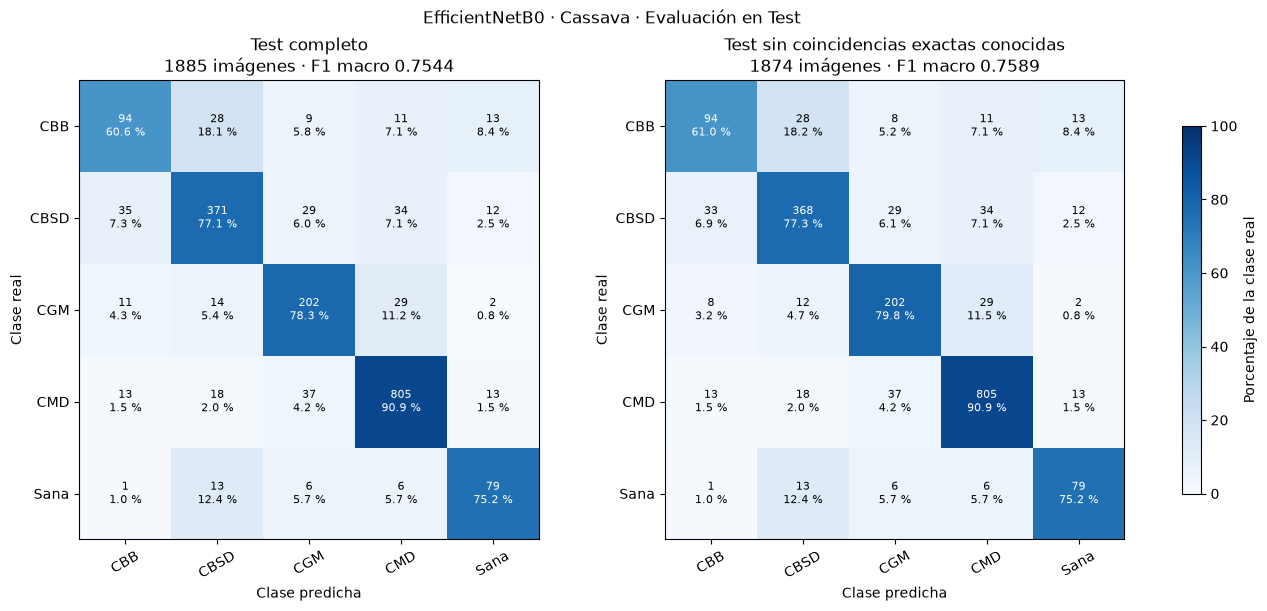

Filas: clase real. Columnas: clase predicha.
Cada casilla muestra cantidad y porcentaje dentro de la clase real.


In [9]:
# PASO 9: Matrices de Test completo y revisión sin coincidencias.
nombres_clases_test = ["CBB", "CBSD", "CGM", "CMD", "Sana"]

fig, ejes = plt.subplots(
    1, 2,
    figsize=(13, 6),
    layout="constrained",
)
fig.suptitle("EfficientNetB0 · Cassava · Evaluación en Test")

comparaciones_test = [
    (
        matriz_test,
        metricas_test,
        "Test completo",
    ),
    (
        matriz_revision_test,
        metricas_revision_test,
        "Test sin coincidencias exactas conocidas",
    ),
]

for eje, (matriz, metricas, titulo) in zip(
    ejes, comparaciones_test
):
    porcentajes = (
        100 * matriz
        / matriz.sum(axis=1, keepdims=True)
    )

    imagen_matriz = eje.imshow(
        porcentajes,
        cmap="Blues",
        vmin=0,
        vmax=100,
    )

    eje.set_xticks(
        range(5),
        labels=nombres_clases_test,
        rotation=30,
    )
    eje.set_yticks(
        range(5),
        labels=nombres_clases_test,
    )
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")
    eje.set_title(
        f"{titulo}\n"
        f"{metricas['imagenes']} imágenes"
        f" · F1 macro {metricas['f1_macro']:.4f}"
    )

    for real, predicha in np.ndindex(matriz.shape):
        porcentaje = porcentajes[real, predicha]

        eje.text(
            predicha,
            real,
            f"{matriz[real, predicha]}\n{porcentaje:.1f} %",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if porcentaje > 50 else "black",
        )

fig.colorbar(
    imagen_matriz,
    ax=ejes.tolist(),
    label="Porcentaje de la clase real",
    shrink=0.8,
)

fig.savefig(
    salida_test / "matrices_confusion_test.png",
    dpi=200,
)
plt.show()
plt.close(fig)

print("Filas: clase real. Columnas: clase predicha.")
print("Cada casilla muestra cantidad y porcentaje dentro de la clase real.")

test-cbb-151.jpg
  Real: cbb | Predicha: cgm | Probabilidad: 33.80%

test-cbsd-382.jpg
  Real: cbsd | Predicha: cbsd | Probabilidad: 72.73%

test-cgm-251.jpg
  Real: cgm | Predicha: cgm | Probabilidad: 88.68%

test-cmd-265.jpg
  Real: cmd | Predicha: cmd | Probabilidad: 98.67%

test-healthy-11.jpg
  Real: healthy | Predicha: healthy | Probabilidad: 91.19%

test-cbsd-199.jpg
  Real: cbsd | Predicha: cgm | Probabilidad: 64.89%



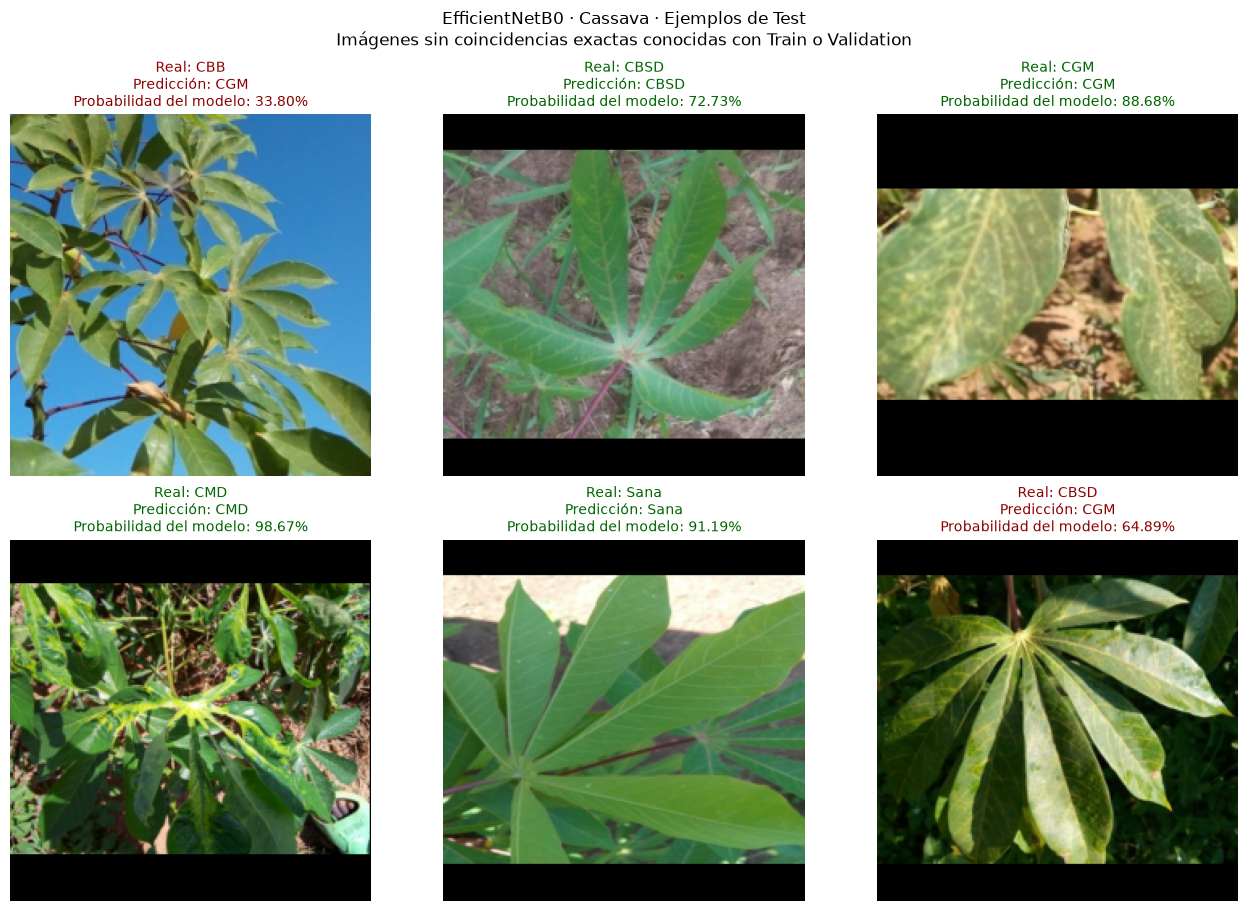

Los ejemplos son ilustrativos.
Las métricas se calcularon sobre los conjuntos completos indicados.
Una probabilidad elevada no garantiza una predicción correcta.
Figuras guardadas en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\comparacion_modelos\validation_20261122_094623_066739\test_modelo_seleccionado


In [10]:
# PASO 10: Un ejemplo por clase y un error adicional.
indices_demo_test = []

for i in range(len(clases)):
    candidatos = np.flatnonzero(
        (reales_test == i) & sin_coincidencias_test
    )

    if candidatos.size == 0:
        raise ValueError(
            f"No hay ejemplos disponibles para {clases[i]}."
        )

    indices_demo_test.append(int(candidatos[0]))

errores_test = np.flatnonzero(
    (reales_test != predichas_test)
    & sin_coincidencias_test
)

for indice in errores_test:
    if int(indice) not in indices_demo_test:
        indices_demo_test.append(int(indice))
        break

# Recuperar solamente las imágenes elegidas.
imagenes_demo_test = {}
pendientes_demo_test = set(indices_demo_test)

for indice, registro in enumerate(ds_test):
    if indice not in pendientes_demo_test:
        continue

    nombre = (
        registro["image/filename"]
        .numpy()
        .decode("utf-8")
    )

    if nombre != nombres_test[indice]:
        raise ValueError(
            "El orden de las imágenes no coincide "
            "con la evaluación de Test."
        )

    imagen, _, _ = preparar_validacion(registro)
    imagenes_demo_test[indice] = imagen.numpy()

    pendientes_demo_test.remove(indice)
    if not pendientes_demo_test:
        break

if pendientes_demo_test:
    raise ValueError(
        "No se recuperaron todos los ejemplos seleccionados."
    )

fig, ejes = plt.subplots(
    2, 3,
    figsize=(13, 9),
    layout="constrained",
)
fig.suptitle(
    "EfficientNetB0 · Cassava · Ejemplos de Test\n"
    "Imágenes sin coincidencias exactas conocidas con Train o Validation"
)

for eje in ejes.flat:
    eje.axis("off")

for eje, indice in zip(ejes.flat, indices_demo_test):
    real = int(reales_test[indice])
    predicha = int(predichas_test[indice])
    probabilidad = float(
        probabilidades_test[indice, predicha]
    )
    acierto = real == predicha

    imagen_visible = np.clip(
        imagenes_demo_test[indice] / 255.0,
        0,
        1,
    )

    eje.imshow(imagen_visible)
    eje.set_title(
        f"Real: {nombres_clases_test[real]}\n"
        f"Predicción: {nombres_clases_test[predicha]}\n"
        f"Probabilidad del modelo: {probabilidad:.2%}",
        fontsize=10,
        color="darkgreen" if acierto else "darkred",
    )

    print(nombres_test[indice])
    print(
        f"  Real: {clases[real]}"
        f" | Predicha: {clases[predicha]}"
        f" | Probabilidad: {probabilidad:.2%}\n"
    )

fig.savefig(
    salida_test / "ejemplos_predicciones_test.png",
    dpi=200,
)
plt.show()
plt.close(fig)

print("Los ejemplos son ilustrativos.")
print("Las métricas se calcularon sobre los conjuntos completos indicados.")
print("Una probabilidad elevada no garantiza una predicción correcta.")
print("Figuras guardadas en:", salida_test.resolve())